<a href="https://colab.research.google.com/github/HimadreeChy/Fuzzy-Random-Forest-Customer-Churn-Prediction/blob/main/fuzzy_rf_churn_project.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
import warnings
warnings.filterwarnings("ignore")

# Display settings
sns.set_theme(style='whitegrid', palette='muted', font_scale=1.05)
pd.set_option('display.max_columns', 200)

# Sklearn
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

# Models
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, GradientBoostingClassifier, AdaBoostClassifier

# Metrics
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, confusion_matrix, classification_report
)

# Handle imbalance
from imblearn.over_sampling import SMOTE

In [ ]:
# Load dataset (adjust path if needed)
df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
print("Shape:", df.shape)
df.head()

# Load dataset (adjust path if needed)
df = pd.read_csv("Bank Customer Churn Prediction.csv")
print("Shape:", df.shape)
df.head()

# Load dataset (adjust path if needed)
df = pd.read_csv("telecom_churn.csv")
print("Shape:", df.shape)
df.head()

Shape: (7043, 21)
Shape: (10000, 12)
Shape: (243553, 14)


,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


In [ ]:
import pandas as pd

# Load all 3 datasets into separate variables
telco_df = pd.read_csv("WA_Fn-UseC_-Telco-Customer-Churn.csv")
bank_df = pd.read_csv("Bank Customer Churn Prediction.csv")
telecom_df = pd.read_csv("telecom_churn.csv")

print("Telco shape:", telco_df.shape)
print("Bank shape:", bank_df.shape)
print("Telecom shape:", telecom_df.shape)

Telco shape: (7043, 21)
Bank shape: (10000, 12)
Telecom shape: (243553, 14)


**Inspect all datasets**

In [ ]:
def inspect_dataset(df, name):
    print("\n" + "="*80)
    print(f"{name.upper()} DATASET OVERVIEW")
    print("="*80)

    print("\nShape:", df.shape)

    print("\nColumns:")
    print(df.columns.tolist())

    print("\nData Types:")
    print(df.dtypes)

    print("\nMissing Values:")
    print(df.isnull().sum())

    print("\nDuplicate Rows:", df.duplicated().sum())

    print("\nFirst 5 Rows:")
    display(df.head())


inspect_dataset(telco_df, "Telco")
inspect_dataset(bank_df, "Bank")
inspect_dataset(telecom_df, "Telecom")


TELCO DATASET OVERVIEW

Shape: (7043, 21)

Columns:
['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data Types:
customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

Missing

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes



BANK DATASET OVERVIEW

Shape: (10000, 12)

Columns:
['customer_id', 'credit_score', 'country', 'gender', 'age', 'tenure', 'balance', 'products_number', 'credit_card', 'active_member', 'estimated_salary', 'churn']

Data Types:
customer_id           int64
credit_score          int64
country              object
gender               object
age                   int64
tenure                int64
balance             float64
products_number       int64
credit_card           int64
active_member         int64
estimated_salary    float64
churn                 int64
dtype: object

Missing Values:
customer_id         0
credit_score        0
country             0
gender              0
age                 0
tenure              0
balance             0
products_number     0
credit_card         0
active_member       0
estimated_salary    0
churn               0
dtype: int64

Duplicate Rows: 0

First 5 Rows:


,customer_id,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,15634602,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,15647311,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,15619304,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,15701354,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,15737888,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0



TELECOM DATASET OVERVIEW

Shape: (243553, 14)

Columns:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']

Data Types:
customer_id              int64
telecom_partner         object
gender                  object
age                      int64
state                   object
city                    object
pincode                  int64
date_of_registration    object
num_dependents           int64
estimated_salary         int64
calls_made               int64
sms_sent                 int64
data_used                int64
churn                    int64
dtype: object

Missing Values:
customer_id             0
telecom_partner         0
gender                  0
age                     0
state                   0
city                    0
pincode                 0
date_of_registration    0
num_dependents          0
estimated_salary        0
calls_made     

,customer_id,telecom_partner,gender,age,state,city,pincode,date_of_registration,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,1,Reliance Jio,F,25,Karnataka,Kolkata,755597,2020-01-01,4,124962,44,45,-361,0
1,2,Reliance Jio,F,55,Mizoram,Mumbai,125926,2020-01-01,2,130556,62,39,5973,0
2,3,Vodafone,F,57,Arunachal Pradesh,Delhi,423976,2020-01-01,0,148828,49,24,193,1
3,4,BSNL,M,46,Tamil Nadu,Kolkata,522841,2020-01-01,1,38722,80,25,9377,1
4,5,BSNL,F,26,Tripura,Delhi,740247,2020-01-01,2,55098,78,15,1393,0


## 4.1 Detailed Exploratory Data Analysis: Telco Dataset

### Boxplot for MonthlyCharges vs. Churn

A boxplot will help us visualize the distribution of `MonthlyCharges` for customers who churned versus those who did not. This can reveal if there's a significant difference in monthly spending patterns between the two groups.

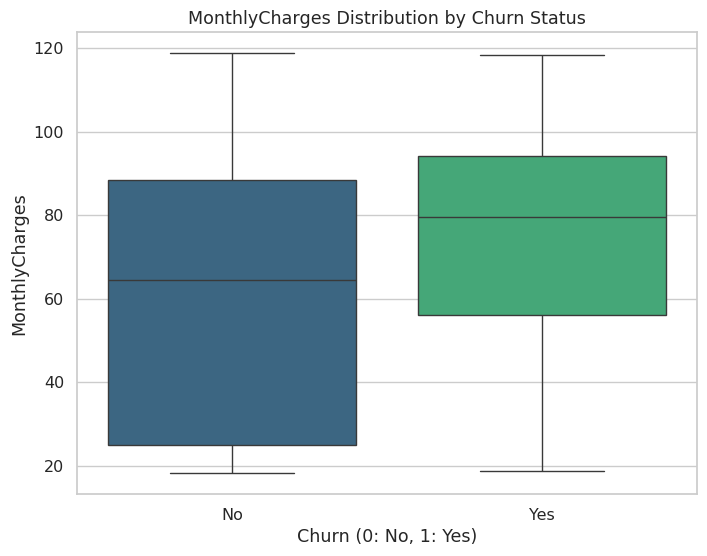

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='Churn', y='MonthlyCharges', data=telco_df, palette='viridis')
plt.title('MonthlyCharges Distribution by Churn Status')
plt.xlabel('Churn (0: No, 1: Yes)')
plt.ylabel('MonthlyCharges')
plt.show()

### Correlation Heatmap for Numerical Features

A heatmap will display the correlation matrix of numerical features in the Telco dataset. This helps in identifying features that are highly correlated with each other or with the target variable, which can be useful for feature selection or understanding multicollinearity.

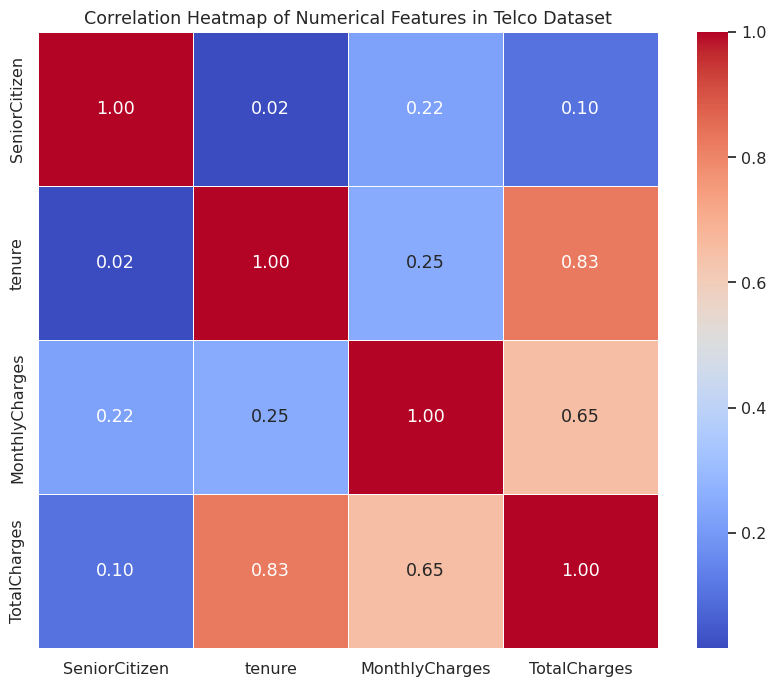

In [ ]:
# Select only numerical columns for correlation calculation
# Exclude 'customerID' and 'TotalCharges' (if not yet converted to numeric or if it has NaNs after conversion)
numerical_telco_df = telco_df.select_dtypes(include=[np.number])

# Ensure 'TotalCharges' is numeric before correlation if it wasn't already handled properly during initial loading
# We already handle it in cell d9ce60cd, so no need for `errors='coerce'` here
if 'TotalCharges' in telco_df.columns and telco_df['TotalCharges'].dtype == 'object':
    numerical_telco_df['TotalCharges'] = pd.to_numeric(telco_df['TotalCharges'], errors='coerce')

# Drop columns that are entirely NaN after conversion or irrelevant for correlation
numerical_telco_df = numerical_telco_df.dropna(axis=1, how='all')

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_telco_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features in Telco Dataset')
plt.show()

## 4.2 Detailed Exploratory Data Analysis: Bank Dataset

### Boxplot for Balance vs. Churn (Bank Dataset)

This boxplot visualizes the distribution of customer balances based on their churn status, helping to identify if there's a financial difference between churning and non-churning customers.

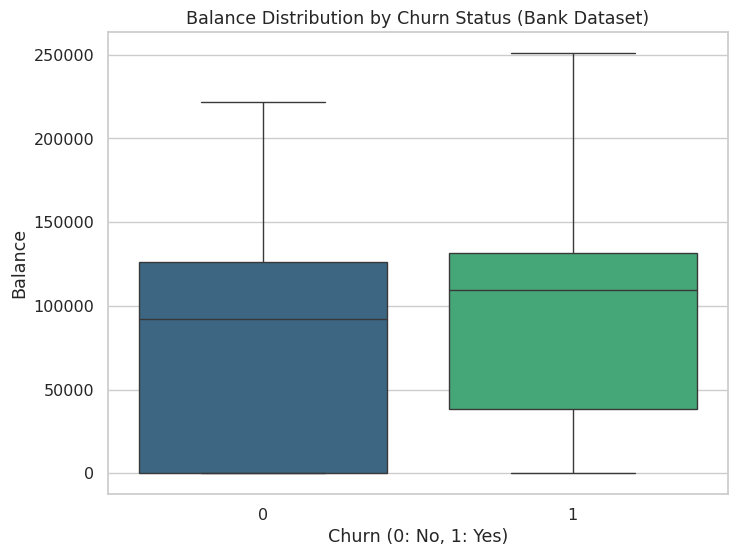

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='churn', y='balance', data=bank_df, palette='viridis')
plt.title('Balance Distribution by Churn Status (Bank Dataset)')
plt.xlabel('Churn (0: No, 1: Yes)')
plt.ylabel('Balance')
plt.show()

### Correlation Heatmap for Numerical Features (Bank Dataset)

This heatmap shows the correlations between numerical features in the Bank dataset, which can reveal important relationships for model building.

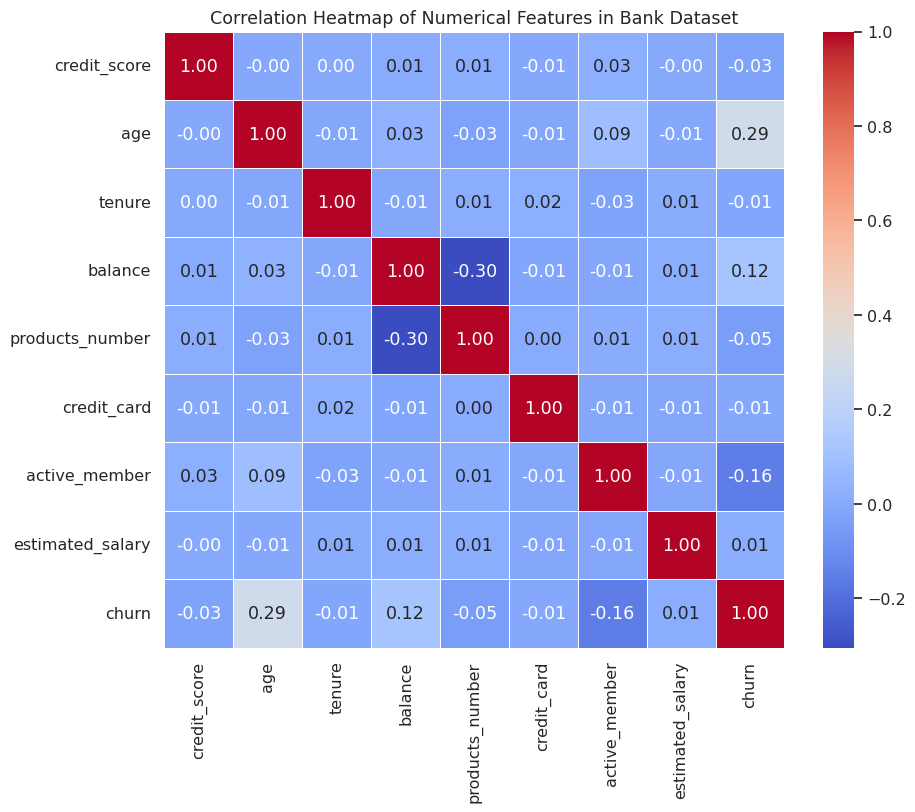

In [ ]:
# Select only numerical columns for correlation calculation
numerical_bank_df = bank_df.select_dtypes(include=[np.number])

# Drop irrelevant identifier columns if they exist
numerical_bank_df = numerical_bank_df.drop(columns=['customer_id'], errors='ignore')

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_bank_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features in Bank Dataset')
plt.show()

## 4.3 Detailed Exploratory Data Analysis: Telecom Dataset

### Boxplot for Data Used vs. Churn (Telecom Dataset)

This boxplot illustrates the distribution of 'data_used' by churn status, indicating whether data consumption patterns differ between those who churn and those who don't.

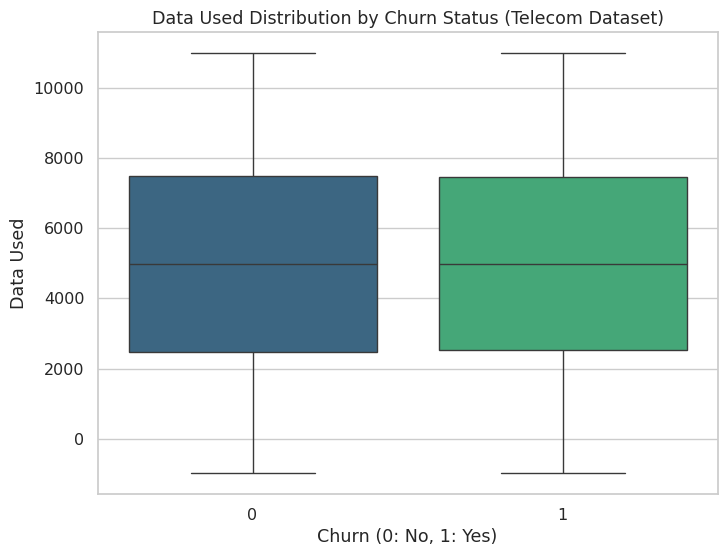

In [ ]:
plt.figure(figsize=(8, 6))
sns.boxplot(x='churn', y='data_used', data=telecom_df, palette='viridis')
plt.title('Data Used Distribution by Churn Status (Telecom Dataset)')
plt.xlabel('Churn (0: No, 1: Yes)')
plt.ylabel('Data Used')
plt.show()

### Correlation Heatmap for Numerical Features (Telecom Dataset)

This heatmap visualizes the correlations among numerical features in the Telecom dataset, providing insights into their interdependencies.

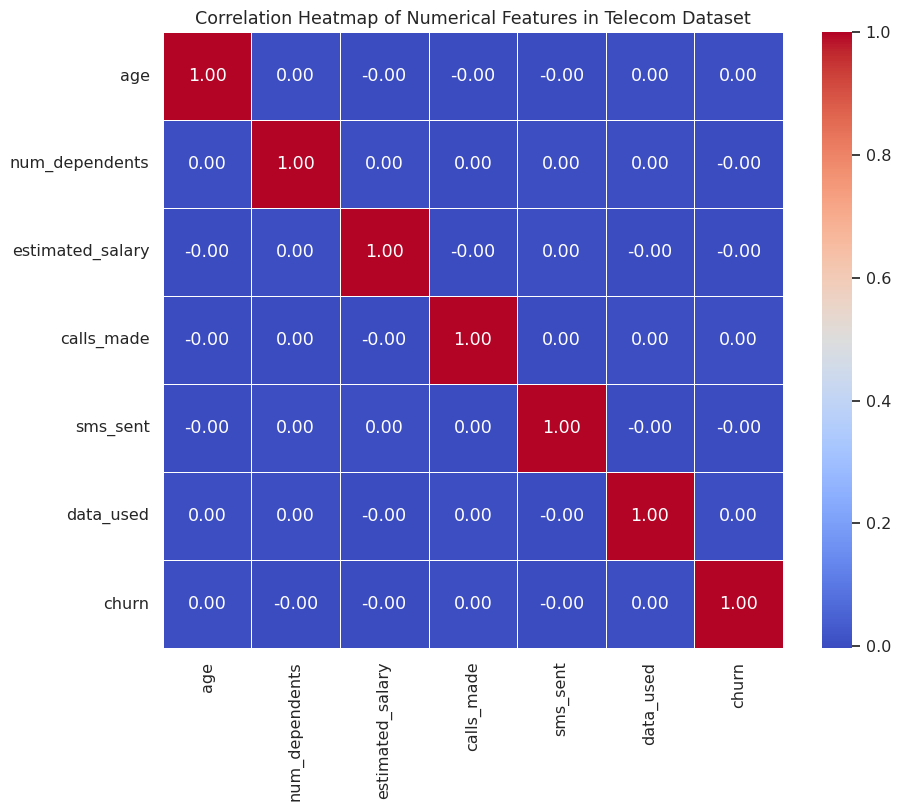

In [ ]:
# Select only numerical columns for correlation calculation
numerical_telecom_df = telecom_df.select_dtypes(include=[np.number])

# Drop irrelevant identifier columns if they exist
numerical_telecom_df = numerical_telecom_df.drop(columns=['customer_id', 'pincode'], errors='ignore')

plt.figure(figsize=(10, 8))
sns.heatmap(numerical_telecom_df.corr(), annot=True, cmap='coolwarm', fmt=".2f", linewidths=.5)
plt.title('Correlation Heatmap of Numerical Features in Telecom Dataset')
plt.show()

**Basic cleaning functions**

In [ ]:
import numpy as np

def basic_cleaning(df):
    df = df.copy()

    # Remove extra spaces from column names
    df.columns = df.columns.str.strip()

    # Strip string values
    for col in df.select_dtypes(include='object').columns:
        df[col] = df[col].astype(str).str.strip()

    return df


def handle_missing_values(df):
    df = df.copy()

    # Fill numeric columns with median
    num_cols = df.select_dtypes(include=np.number).columns
    for col in num_cols:
        df[col] = df[col].fillna(df[col].median())

    # Fill categorical columns with mode
    cat_cols = df.select_dtypes(exclude=np.number).columns
    for col in cat_cols:
        if not df[col].mode().empty:
            df[col] = df[col].fillna(df[col].mode()[0])
        else:
            df[col] = df[col].fillna("Unknown")

    return df

**Clean Telco dataset**

In [ ]:
telecom = telecom_df.copy()
telecom = basic_cleaning(telecom)

print("Telecom columns:")
print(telecom.columns.tolist())

Telecom columns:
['customer_id', 'telecom_partner', 'gender', 'age', 'state', 'city', 'pincode', 'date_of_registration', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used', 'churn']


In [ ]:
telecom = telecom_df.copy()
telecom = basic_cleaning(telecom)

# Drop ID/date/location columns if they are not useful
drop_cols = ["customer_id", "date_of_registration", "pincode", "state", "city"]
drop_existing = [col for col in drop_cols if col in telecom.columns]
telecom.drop(columns=drop_existing, inplace=True, errors="ignore")

# If telecom has target column named churn
if "churn" in telecom.columns:
    telecom["churn"] = telecom["churn"].map({"Yes": 1, "No": 0}) if telecom["churn"].dtype == 'object' else telecom["churn"]

# Handle missing values
telecom = handle_missing_values(telecom)

print("Telecom cleaned shape:", telecom.shape)
display(telecom.head())

Telecom cleaned shape: (243553, 9)


,telecom_partner,gender,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,churn
0,Reliance Jio,F,25,4,124962,44,45,-361,0
1,Reliance Jio,F,55,2,130556,62,39,5973,0
2,Vodafone,F,57,0,148828,49,24,193,1
3,BSNL,M,46,1,38722,80,25,9377,1
4,BSNL,F,26,2,55098,78,15,1393,0


**Clean Telco dataset**

In [ ]:
telco = telco_df.copy()
telco = basic_cleaning(telco)

# Convert 'TotalCharges' to numeric, coercing errors to NaN
telco['TotalCharges'] = pd.to_numeric(telco['TotalCharges'], errors='coerce')

# Drop customerID as it's an identifier and not useful for modeling
telco.drop(columns=['customerID'], inplace=True, errors='ignore')

# Map 'Yes'/'No' in 'Churn' to 1/0
telco['Churn'] = telco['Churn'].map({'Yes': 1, 'No': 0})

# Handle missing values after converting TotalCharges
telco = handle_missing_values(telco)

print("Telco cleaned shape:", telco.shape)
display(telco.head())

Telco cleaned shape: (7043, 20)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,0
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.50,0
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,1
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,0
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,1


**Clean Bank dataset**

In [ ]:
bank = bank_df.copy()
bank = basic_cleaning(bank)

# Drop customer_id as it's an identifier and not useful for modeling
bank.drop(columns=['customer_id'], inplace=True, errors='ignore')

# Handle missing values
bank = handle_missing_values(bank)

print("Bank cleaned shape:", bank.shape)
display(bank.head())

Bank cleaned shape: (10000, 11)


,credit_score,country,gender,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,churn
0,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


## 7. Data Preprocessing

In [ ]:
def preprocess_data(df, target_column):
    # Separate target variable
    X = df.drop(columns=[target_column])
    y = df[target_column]

    # Identify categorical and numerical columns
    categorical_cols = X.select_dtypes(include='object').columns
    numerical_cols = X.select_dtypes(include=['int64', 'float64']).columns

    # Create a preprocessor using ColumnTransformer
    preprocessor = ColumnTransformer(
        transformers=[
            ('num', StandardScaler(), numerical_cols),
            ('cat', OneHotEncoder(handle_unknown='ignore'), categorical_cols)
        ],
        remainder='passthrough' # Keep other columns (if any) as they are
    )

    # Apply preprocessing
    X_processed = preprocessor.fit_transform(X)

    # Get feature names after one-hot encoding
    ohe_feature_names = preprocessor.named_transformers_['cat'].get_feature_names_out(categorical_cols)
    all_feature_names = list(numerical_cols) + list(ohe_feature_names)

    # Convert to DataFrame for easier handling, if needed later
    X_processed_df = pd.DataFrame(X_processed, columns=all_feature_names)

    print(f"Original features: {X.shape[1]}, Processed features: {X_processed_df.shape[1]}")
    print(f"Target distribution:\n{y.value_counts(normalize=True)}")

    return X_processed_df, y, preprocessor


**Preprocess Telco Data**

In [ ]:
X_telco, y_telco, telco_preprocessor = preprocess_data(telco, 'Churn')
print("\nTelco preprocessed shape:", X_telco.shape)
display(X_telco.head())

Original features: 19, Processed features: 45
Target distribution:
Churn
0    0.73463
1    0.26537
Name: proportion, dtype: float64

Telco preprocessed shape: (7043, 45)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,-0.439916,-1.277445,-1.160323,-0.994242,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0
1,-0.439916,0.066327,-0.259629,-0.173244,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0
2,-0.439916,-1.236724,-0.362660,-0.959674,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0
3,-0.439916,0.514251,-0.746535,-0.194766,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0
4,-0.439916,-1.236724,0.197365,-0.940470,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0


**Preprocess Bank Data**

In [ ]:
X_bank, y_bank, bank_preprocessor = preprocess_data(bank, 'churn')
print("\nBank preprocessed shape:", X_bank.shape)
display(X_bank.head())

Original features: 10, Processed features: 13
Target distribution:
churn
0    0.7963
1    0.2037
Name: proportion, dtype: float64

Bank preprocessed shape: (10000, 13)


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_France,country_Germany,country_Spain,gender_Female,gender_Male
0,-0.326221,0.293517,-1.041760,-1.225848,-0.911583,0.646092,0.970243,0.021886,1.0,0.0,0.0,1.0,0.0
1,-0.440036,0.198164,-1.387538,0.117350,-0.911583,-1.547768,0.970243,0.216534,0.0,0.0,1.0,1.0,0.0
2,-1.536794,0.293517,1.032908,1.333053,2.527057,0.646092,-1.030670,0.240687,1.0,0.0,0.0,1.0,0.0
3,0.501521,0.007457,-1.387538,-1.225848,0.807737,-1.547768,-1.030670,-0.108918,1.0,0.0,0.0,1.0,0.0
4,2.063884,0.388871,-1.041760,0.785728,-0.911583,0.646092,0.970243,-0.365276,0.0,0.0,1.0,1.0,0.0


**Preprocess Telecom Data**

In [ ]:
X_telecom, y_telecom, telecom_preprocessor = preprocess_data(telecom, 'churn')
print("\nTelecom preprocessed shape:", X_telecom.shape)
display(X_telecom.head())

Original features: 8, Processed features: 12
Target distribution:
churn
0    0.799522
1    0.200478
Name: proportion, dtype: float64

Telecom preprocessed shape: (243553, 12)


,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,telecom_partner_Airtel,telecom_partner_BSNL,telecom_partner_Reliance Jio,telecom_partner_Vodafone,gender_F,gender_M
0,-1.281782,1.415256,1.064837,-0.170117,1.429025,-1.819905,0.0,0.0,1.0,0.0,1.0,0.0
1,0.542593,0.001767,1.213975,0.441016,1.021791,0.333042,0.0,0.0,1.0,0.0,1.0,0.0
2,0.664218,-1.411722,1.701113,-0.000358,0.003706,-1.631599,0.0,0.0,0.0,1.0,1.0,0.0
3,-0.004720,-0.704977,-1.234351,1.052149,0.071578,1.490073,0.0,1.0,0.0,0.0,0.0,1.0
4,-1.220969,0.001767,-0.797761,0.984245,-0.607145,-1.223715,0.0,1.0,0.0,0.0,1.0,0.0


## 8. Fuzzy Membership Function Design

Fuzzy logic allows us to deal with concepts that are not strictly true or false, but rather have degrees of truth. A fuzzy membership function assigns a degree of membership (a value between 0 and 1) to each data point for a given fuzzy set (e.g., 'low', 'medium', 'high'). This can help in capturing non-linear relationships and human-like reasoning.

We will design membership functions for key numerical features in each dataset. We'll use simple triangular or trapezoidal membership functions for demonstration purposes.

In [ ]:
# Import necessary libraries for fuzzy logic (if not already imported)
# For this example, we'll implement simple functions, but libraries like 'scikit-fuzzy' could be used for more complex scenarios.

# Helper function to plot membership functions (optional, for visualization)
def plot_membership_functions(feature_name, membership_funcs):
    plt.figure(figsize=(8, 4))
    x = np.linspace(min(val for mf in membership_funcs for val in mf['points']),
                    max(val for mf in membership_funcs for val in mf['points']), 500)

    for mf in membership_funcs:
        if mf['type'] == 'triangular':
            y = [max(0, min((val - mf['points'][0]) / (mf['points'][1] - mf['points'][0]) if (mf['points'][1] - mf['points'][0]) != 0 else 1,
                            (mf['points'][2] - val) / (mf['points'][2] - mf['points'][1]) if (mf['points'][2] - mf['points'][1]) != 0 else 1)) for val in x]
        elif mf['type'] == 'trapezoidal':
            y = [max(0, min((val - mf['points'][0]) / (mf['points'][1] - mf['points'][0]) if (mf['points'][1] - mf['points'][0]) != 0 else 1,
                            1,
                            (mf['points'][3] - val) / (mf['points'][3] - mf['points'][2]) if (mf['points'][3] - mf['points'][2]) != 0 else 1)) for val in x]
        else: # assuming 'left_shoulder' or 'right_shoulder' type
            if mf['type'] == 'left_shoulder':
                y = [min(1, max(0, (mf['points'][1] - val) / (mf['points'][1] - mf['points'][0]))) for val in x]
            elif mf['type'] == 'right_shoulder':
                y = [min(1, max(0, (val - mf['points'][0]) / (mf['points'][1] - mf['points'][0]))) for val in x]
            else:
                y = [0 for val in x]

        plt.plot(x, y, label=mf['name'])

    plt.title(f'Membership Functions for {feature_name}')
    plt.xlabel(feature_name)
    plt.ylabel('Degree of Membership')
    plt.legend()
    plt.grid(True)
    plt.show()


# Placeholder for defining fuzzy sets for Telco dataset
# We will need to analyze distributions first to define these effectively.
# Example for 'tenure' (customer tenure in months)
print("\n--- Analyzing Telco numerical features for fuzzification ---")
display(telco[['tenure', 'MonthlyCharges', 'TotalCharges']].describe())

# Example of how membership functions might be defined for 'tenure'
# This will be refined based on actual data distribution
telco_fuzzy_sets = {
    'tenure': [
        {'name': 'new_customer', 'type': 'left_shoulder', 'points': [0, 12]}, # 0 to 12 months, fully member at 0, 0 member at 12
        {'name': 'mid_term_customer', 'type': 'triangular', 'points': [6, 36, 60]}, # triangular from 6 to 60, peak at 36
        {'name': 'long_term_customer', 'type': 'right_shoulder', 'points': [48, 72]} # 48 to 72 months, fully member at 72
    ],
    'MonthlyCharges': [
        {'name': 'low_charge', 'type': 'left_shoulder', 'points': [18, 40]},
        {'name': 'medium_charge', 'type': 'triangular', 'points': [30, 60, 90]},
        {'name': 'high_charge', 'type': 'right_shoulder', 'points': [80, 120]}
    ]
    # Add more features and their fuzzy sets as needed
}

# plot_membership_functions('tenure', telco_fuzzy_sets['tenure'])
# plot_membership_functions('MonthlyCharges', telco_fuzzy_sets['MonthlyCharges'])


# Placeholder for defining fuzzy sets for Bank dataset
print("\n--- Analyzing Bank numerical features for fuzzification ---")
display(bank[['credit_score', 'age', 'balance', 'estimated_salary']].describe())

bank_fuzzy_sets = {
    'credit_score': [
        {'name': 'low_score', 'type': 'right_shoulder', 'points': [350, 600]}, # example range
        {'name': 'medium_score', 'type': 'triangular', 'points': [500, 700, 850]}, # example range
        {'name': 'high_score', 'type': 'left_shoulder', 'points': [750, 850]}  # example range
    ],
    'age': [
        {'name': 'young', 'type': 'left_shoulder', 'points': [18, 30]},
        {'name': 'middle_aged', 'type': 'triangular', 'points': [25, 45, 65]},
        {'name': 'senior', 'type': 'right_shoulder', 'points': [60, 90]}
    ]
}

# plot_membership_functions('credit_score', bank_fuzzy_sets['credit_score'])
# plot_membership_functions('age', bank_fuzzy_sets['age'])


# Placeholder for defining fuzzy sets for Telecom dataset
print("\n--- Analyzing Telecom numerical features for fuzzification ---")
display(telecom[['age', 'num_dependents', 'estimated_salary', 'calls_made', 'sms_sent', 'data_used']].describe())

telecom_fuzzy_sets = {
    'age': [
        {'name': 'young', 'type': 'left_shoulder', 'points': [18, 30]},
        {'name': 'middle_aged', 'type': 'triangular', 'points': [25, 45, 65]},
        {'name': 'senior', 'type': 'right_shoulder', 'points': [60, 90]}
    ],
    'data_used': [
        {'name': 'low_usage', 'type': 'left_shoulder', 'points': [0, 1000]},
        {'name': 'medium_usage', 'type': 'triangular', 'points': [500, 5000, 10000]},
        {'name': 'high_usage', 'type': 'right_shoulder', 'points': [8000, 20000]}
    ]
}

# plot_membership_functions('data_used', telecom_fuzzy_sets['data_used'])


# A function to apply these fuzzy sets to a dataframe
def generate_fuzzy_features(df, fuzzy_sets_config):
    df_fuzzy = df.copy()
    for feature, mfs in fuzzy_sets_config.items():
        for mf in mfs:
            fuzzy_feature_name = f"{feature}_{mf['name']}"
            if mf['type'] == 'triangular':
                # a, b, c for triangular (a <= b <= c, b is peak)
                a, b, c = mf['points']
                df_fuzzy[fuzzy_feature_name] = df_fuzzy[feature].apply(lambda x:
                    max(0, min((x - a) / (b - a) if (b - a) != 0 else 1,
                                (c - x) / (c - b) if (c - b) != 0 else 1))
                )
            elif mf['type'] == 'trapezoidal':
                # a, b, c, d for trapezoidal (a <= b <= c <= d)
                a, b, c, d = mf['points']
                df_fuzzy[fuzzy_feature_name] = df_fuzzy[feature].apply(lambda x:
                    max(0, min((x - a) / (b - a) if (b - a) != 0 else 1,
                                1,
                                (d - x) / (d - c) if (d - c) != 0 else 1))
                )
            elif mf['type'] == 'left_shoulder':
                # a, b for left shoulder (a is start of slope, b is end of slope where membership becomes 0)
                a, b = mf['points']
                df_fuzzy[fuzzy_feature_name] = df_fuzzy[feature].apply(lambda x:
                    min(1, max(0, (b - x) / (b - a)))
                )
            elif mf['type'] == 'right_shoulder':
                # a, b for right shoulder (a is start of slope where membership becomes 0, b is end of slope where membership becomes 1)
                a, b = mf['points']
                df_fuzzy[fuzzy_feature_name] = df_fuzzy[feature].apply(lambda x:
                    min(1, max(0, (x - a) / (b - a)))
                )
    return df_fuzzy



--- Analyzing Telco numerical features for fuzzification ---


,tenure,MonthlyCharges,TotalCharges
count,7043.000000,7043.000000,7043.000000
mean,32.371149,64.761692,2281.916928
std,24.559481,30.090047,2265.270398
min,0.000000,18.250000,18.800000
25%,9.000000,35.500000,402.225000
50%,29.000000,70.350000,1397.475000
75%,55.000000,89.850000,3786.600000
max,72.000000,118.750000,8684.800000



--- Analyzing Bank numerical features for fuzzification ---


,credit_score,age,balance,estimated_salary
count,10000.000000,10000.000000,10000.000000,10000.000000
mean,650.528800,38.921800,76485.889288,100090.239881
std,96.653299,10.487806,62397.405202,57510.492818
min,350.000000,18.000000,0.000000,11.580000
25%,584.000000,32.000000,0.000000,51002.110000
50%,652.000000,37.000000,97198.540000,100193.915000
75%,718.000000,44.000000,127644.240000,149388.247500
max,850.000000,92.000000,250898.090000,199992.480000



--- Analyzing Telecom numerical features for fuzzification ---


,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used
count,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000,243553.000000
mean,46.077609,1.997500,85021.137839,49.010548,23.945404,4993.186025
std,16.444029,1.414941,37508.963233,29.453556,14.733575,2942.019547
min,18.000000,0.000000,20000.000000,-10.000000,-5.000000,-987.000000
25%,32.000000,1.000000,52585.000000,24.000000,11.000000,2490.000000
50%,46.000000,2.000000,84990.000000,49.000000,24.000000,4987.000000
75%,60.000000,3.000000,117488.000000,74.000000,36.000000,7493.000000
max,74.000000,4.000000,149999.000000,108.000000,53.000000,10991.000000


## 9. Fuzzy Feature Generation

**Generate Fuzzy Features for Telco Dataset**

In [ ]:
X_telco_fuzzy = generate_fuzzy_features(X_telco, telco_fuzzy_sets)
print("Telco X with fuzzy features shape:", X_telco_fuzzy.shape)
display(X_telco_fuzzy.head())

Telco X with fuzzy features shape: (7043, 51)


,SeniorCitizen,tenure,MonthlyCharges,TotalCharges,gender_Female,gender_Male,Partner_No,Partner_Yes,Dependents_No,Dependents_Yes,PhoneService_No,PhoneService_Yes,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaperlessBilling_No,PaperlessBilling_Yes,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check,tenure_new_customer,tenure_mid_term_customer,tenure_long_term_customer,MonthlyCharges_low_charge,MonthlyCharges_medium_charge,MonthlyCharges_high_charge
0,-0.439916,-1.277445,-1.160323,-0.994242,1.0,0.0,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.000000,0,0,1,0,0
1,-0.439916,0.066327,-0.259629,-0.173244,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.994473,0,0,1,0,0
2,-0.439916,-1.236724,-0.362660,-0.959674,0.0,1.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,1.000000,0,0,1,0,0
3,-0.439916,0.514251,-0.746535,-0.194766,0.0,1.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,1.0,0.0,0.0,0.0,0.957146,0,0,1,0,0
4,-0.439916,-1.236724,0.197365,-0.940470,1.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,1.0,0.0,0.0,0.0,1.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,1.000000,0,0,1,0,0


**Generate Fuzzy Features for Bank Dataset**

In [ ]:
X_bank_fuzzy = generate_fuzzy_features(X_bank, bank_fuzzy_sets)
print("Bank X with fuzzy features shape:", X_bank_fuzzy.shape)
display(X_bank_fuzzy.head())

Bank X with fuzzy features shape: (10000, 19)


,credit_score,age,tenure,balance,products_number,credit_card,active_member,estimated_salary,country_France,country_Germany,country_Spain,gender_Female,gender_Male,credit_score_low_score,credit_score_medium_score,credit_score_high_score,age_young,age_middle_aged,age_senior
0,-0.326221,0.293517,-1.041760,-1.225848,-0.911583,0.646092,0.970243,0.021886,1.0,0.0,0.0,1.0,0.0,0,0,1,1,0,0
1,-0.440036,0.198164,-1.387538,0.117350,-0.911583,-1.547768,0.970243,0.216534,0.0,0.0,1.0,1.0,0.0,0,0,1,1,0,0
2,-1.536794,0.293517,1.032908,1.333053,2.527057,0.646092,-1.030670,0.240687,1.0,0.0,0.0,1.0,0.0,0,0,1,1,0,0
3,0.501521,0.007457,-1.387538,-1.225848,0.807737,-1.547768,-1.030670,-0.108918,1.0,0.0,0.0,1.0,0.0,0,0,1,1,0,0
4,2.063884,0.388871,-1.041760,0.785728,-0.911583,0.646092,0.970243,-0.365276,0.0,0.0,1.0,1.0,0.0,0,0,1,1,0,0


**Generate Fuzzy Features for Telecom Dataset**

In [ ]:
X_telecom_fuzzy = generate_fuzzy_features(X_telecom, telecom_fuzzy_sets)
print("Telecom X with fuzzy features shape:", X_telecom_fuzzy.shape)
display(X_telecom_fuzzy.head())

Telecom X with fuzzy features shape: (243553, 18)


,age,num_dependents,estimated_salary,calls_made,sms_sent,data_used,telecom_partner_Airtel,telecom_partner_BSNL,telecom_partner_Reliance Jio,telecom_partner_Vodafone,gender_F,gender_M,age_young,age_middle_aged,age_senior,data_used_low_usage,data_used_medium_usage,data_used_high_usage
0,-1.281782,1.415256,1.064837,-0.170117,1.429025,-1.819905,0.0,0.0,1.0,0.0,1.0,0.0,1,0,0,1.000000,0,0
1,0.542593,0.001767,1.213975,0.441016,1.021791,0.333042,0.0,0.0,1.0,0.0,1.0,0.0,1,0,0,0.999667,0,0
2,0.664218,-1.411722,1.701113,-0.000358,0.003706,-1.631599,0.0,0.0,0.0,1.0,1.0,0.0,1,0,0,1.000000,0,0
3,-0.004720,-0.704977,-1.234351,1.052149,0.071578,1.490073,0.0,1.0,0.0,0.0,0.0,1.0,1,0,0,0.998510,0,0
4,-1.220969,0.001767,-0.797761,0.984245,-0.607145,-1.223715,0.0,1.0,0.0,0.0,1.0,0.0,1,0,0,1.000000,0,0


## 10. Fuzzy Random Forest

In [ ]:
def train_and_evaluate_fuzzy_rf(X_fuzzy, y, dataset_name):
    print(f"\n--- Fuzzy Random Forest for {dataset_name} Dataset ---")
    # Split data (using the same stratification as before)
    X_train, X_test, y_train, y_test = train_test_split(X_fuzzy, y, test_size=0.3, random_state=42, stratify=y)

    # Initialize and train Random Forest Classifier
    fuzzy_rf_model = RandomForestClassifier(random_state=42)
    fuzzy_rf_model.fit(X_train, y_train)

    # Make predictions
    y_pred = fuzzy_rf_model.predict(X_test)
    y_prob = fuzzy_rf_model.predict_proba(X_test)[:, 1]

    # Evaluate performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Greens')
    plt.title(f'Confusion Matrix - Fuzzy RF {dataset_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return fuzzy_rf_model, accuracy, precision, recall, f1, roc_auc


**Fuzzy Random Forest for Telco Dataset**


--- Fuzzy Random Forest for Telco Dataset ---
Accuracy: 0.7795
Precision: 0.6063
Recall: 0.4831
F1-Score: 0.5377
ROC AUC: 0.8174

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1552
           1       0.61      0.48      0.54       561

    accuracy                           0.78      2113
   macro avg       0.72      0.68      0.70      2113
weighted avg       0.77      0.78      0.77      2113


Confusion Matrix:


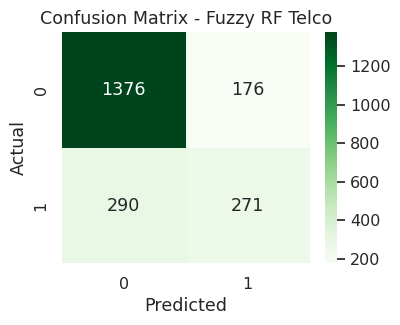

In [ ]:
fuzzy_rf_telco, f_acc_telco, f_prec_telco, f_rec_telco, f_f1_telco, f_auc_telco = train_and_evaluate_fuzzy_rf(X_telco_fuzzy, y_telco, "Telco")

**Fuzzy Random Forest for Bank Dataset**


--- Fuzzy Random Forest for Bank Dataset ---
Accuracy: 0.8640
Precision: 0.7812
Recall: 0.4615
F1-Score: 0.5802
ROC AUC: 0.8589

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.97      0.92      2389
           1       0.78      0.46      0.58       611

    accuracy                           0.86      3000
   macro avg       0.83      0.71      0.75      3000
weighted avg       0.86      0.86      0.85      3000


Confusion Matrix:


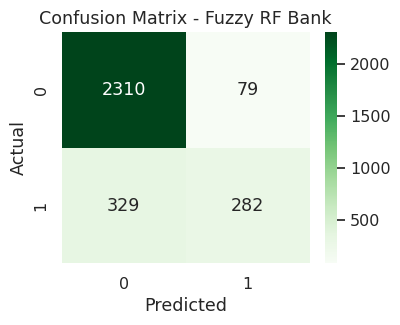

In [ ]:
fuzzy_rf_bank, f_acc_bank, f_prec_bank, f_rec_bank, f_f1_bank, f_auc_bank = train_and_evaluate_fuzzy_rf(X_bank_fuzzy, y_bank, "Bank")

**Fuzzy Random Forest for Telecom Dataset**


--- Fuzzy Random Forest for Telecom Dataset ---
Accuracy: 0.7990
Precision: 0.2174
Recall: 0.0010
F1-Score: 0.0020
ROC AUC: 0.4980

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     58418
           1       0.22      0.00      0.00     14648

    accuracy                           0.80     73066
   macro avg       0.51      0.50      0.45     73066
weighted avg       0.68      0.80      0.71     73066


Confusion Matrix:


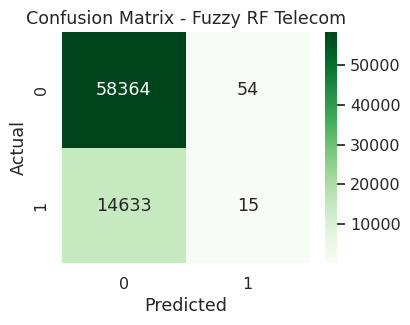

In [ ]:
fuzzy_rf_telecom, f_acc_telecom, f_prec_telecom, f_rec_telecom, f_f1_telecom, f_auc_telecom = train_and_evaluate_fuzzy_rf(X_telecom_fuzzy, y_telecom, "Telecom")

## 11. Baseline Random Forest Models

In [ ]:
def train_and_evaluate_rf(X, y, dataset_name):
    print(f"\n--- {dataset_name} Dataset ---")
    # Split data
    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    # Initialize and train Random Forest Classifier
    rf_model = RandomForestClassifier(random_state=42)
    rf_model.fit(X_train, y_train)

    # Make predictions
    y_pred = rf_model.predict(X_test)
    y_prob = rf_model.predict_proba(X_test)[:, 1]

    # Evaluate performance
    accuracy = accuracy_score(y_test, y_pred)
    precision = precision_score(y_test, y_pred)
    recall = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    roc_auc = roc_auc_score(y_test, y_prob)

    print(f"Accuracy: {accuracy:.4f}")
    print(f"Precision: {precision:.4f}")
    print(f"Recall: {recall:.4f}")
    print(f"F1-Score: {f1:.4f}")
    print(f"ROC AUC: {roc_auc:.4f}")

    print("\nClassification Report:")
    print(classification_report(y_test, y_pred))

    print("\nConfusion Matrix:")
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(4, 3))
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')
    plt.title(f'Confusion Matrix - {dataset_name}')
    plt.xlabel('Predicted')
    plt.ylabel('Actual')
    plt.show()

    return rf_model, accuracy, precision, recall, f1, roc_auc

### Training and Evaluation of Baseline Models


--- Telco Dataset ---
Accuracy: 0.7837
Precision: 0.6171
Recall: 0.4884
F1-Score: 0.5453
ROC AUC: 0.8131

Classification Report:
              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1552
           1       0.62      0.49      0.55       561

    accuracy                           0.78      2113
   macro avg       0.72      0.69      0.70      2113
weighted avg       0.77      0.78      0.78      2113


Confusion Matrix:


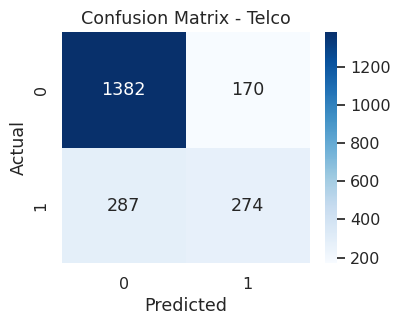

In [ ]:
rf_telco, acc_telco, prec_telco, rec_telco, f1_telco, auc_telco = train_and_evaluate_rf(X_telco, y_telco, "Telco")


--- Bank Dataset ---
Accuracy: 0.8633
Precision: 0.7799
Recall: 0.4583
F1-Score: 0.5773
ROC AUC: 0.8600

Classification Report:
              precision    recall  f1-score   support

           0       0.87      0.97      0.92      2389
           1       0.78      0.46      0.58       611

    accuracy                           0.86      3000
   macro avg       0.83      0.71      0.75      3000
weighted avg       0.86      0.86      0.85      3000


Confusion Matrix:


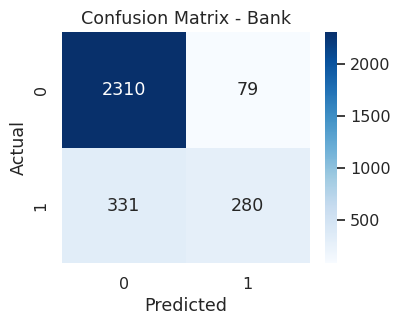

In [ ]:
rf_bank, acc_bank, prec_bank, rec_bank, f1_bank, auc_bank = train_and_evaluate_rf(X_bank, y_bank, "Bank")


--- Telecom Dataset ---
Accuracy: 0.7991
Precision: 0.2203
Recall: 0.0009
F1-Score: 0.0018
ROC AUC: 0.4985

Classification Report:
              precision    recall  f1-score   support

           0       0.80      1.00      0.89     58418
           1       0.22      0.00      0.00     14648

    accuracy                           0.80     73066
   macro avg       0.51      0.50      0.45     73066
weighted avg       0.68      0.80      0.71     73066


Confusion Matrix:


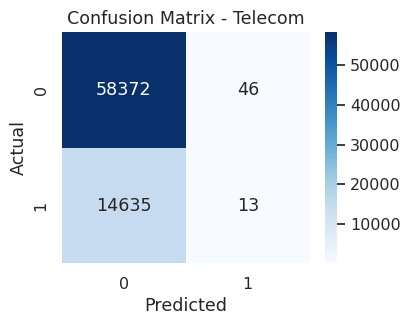

In [ ]:
rf_telecom, acc_telecom, prec_telecom, rec_telecom, f1_telecom, auc_telecom = train_and_evaluate_rf(X_telecom, y_telecom, "Telecom")

## 12. Model Evaluation and Performance Comparison

In [ ]:
results_data = {
    'Dataset': ['Telco', 'Bank', 'Telecom', 'Telco (Fuzzy)', 'Bank (Fuzzy)', 'Telecom (Fuzzy)'],
    'Accuracy': [acc_telco, acc_bank, acc_telecom, f_acc_telco, f_acc_bank, f_acc_telecom],
    'Precision': [prec_telco, prec_bank, prec_telecom, f_prec_telco, f_prec_bank, f_prec_telecom],
    'Recall': [rec_telco, rec_bank, rec_telecom, f_rec_telco, f_rec_bank, f_rec_telecom],
    'F1-Score': [f1_telco, f1_bank, f1_telecom, f_f1_telco, f_f1_bank, f_f1_telecom],
    'ROC AUC': [auc_telco, auc_bank, auc_telecom, f_auc_telco, f_auc_bank, f_auc_telecom]
}

results_df = pd.DataFrame(results_data)
display(results_df.round(4))

,Dataset,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Telco,0.7837,0.6171,0.4884,0.5453,0.8131
1,Bank,0.8633,0.7799,0.4583,0.5773,0.8600
2,Telecom,0.7991,0.2203,0.0009,0.0018,0.4985
3,Telco (Fuzzy),0.7795,0.6063,0.4831,0.5377,0.8174
4,Bank (Fuzzy),0.8640,0.7812,0.4615,0.5802,0.8589
5,Telecom (Fuzzy),0.7990,0.2174,0.0010,0.0020,0.4980



--- Performance Comparison Table ---


,Dataset,Accuracy,Precision,Recall,F1-Score,ROC AUC
0,Telco,0.7837,0.6171,0.4884,0.5453,0.8131
1,Bank,0.8633,0.7799,0.4583,0.5773,0.8600
2,Telecom,0.7991,0.2203,0.0009,0.0018,0.4985
3,Telco (Fuzzy),0.7795,0.6063,0.4831,0.5377,0.8174
4,Bank (Fuzzy),0.8640,0.7812,0.4615,0.5802,0.8589
5,Telecom (Fuzzy),0.7990,0.2174,0.0010,0.0020,0.4980



--- Analysis of Performance Changes ---

Dataset: Telco
  Accuracy: Baseline = 0.7837, Fuzzy = 0.7795, Change = -0.54%
  Precision: Baseline = 0.6171, Fuzzy = 0.6063, Change = -1.76%
  Recall: Baseline = 0.4884, Fuzzy = 0.4831, Change = -1.09%
  F1-Score: Baseline = 0.5453, Fuzzy = 0.5377, Change = -1.39%
  ROC AUC: Baseline = 0.8131, Fuzzy = 0.8174, Change = 0.52%

Dataset: Bank
  Accuracy: Baseline = 0.8633, Fuzzy = 0.8640, Change = 0.08%
  Precision: Baseline = 0.7799, Fuzzy = 0.7812, Change = 0.16%
  Recall: Baseline = 0.4583, Fuzzy = 0.4615, Change = 0.71%
  F1-Score: Baseline = 0.5773, Fuzzy = 0.5802, Change = 0.51%
  ROC AUC: Baseline = 0.8600, Fuzzy = 0.8589, Change = -0.13%

Dataset: Telecom
  Accuracy: Baseline = 0.7991, Fuzzy = 0.7990, Change = -0.01%
  Precision: Baseline = 0.2203, Fuzzy = 0.2174, Change = -1.34%
  Recall: Baseline = 0.0009, Fuzzy = 0.0010, Change = 15.38%
  F1-Score: Baseline = 0.0018, Fuzzy = 0.0020, Change = 15.31%
  ROC AUC: Baseline = 0.4985, Fuzzy = 

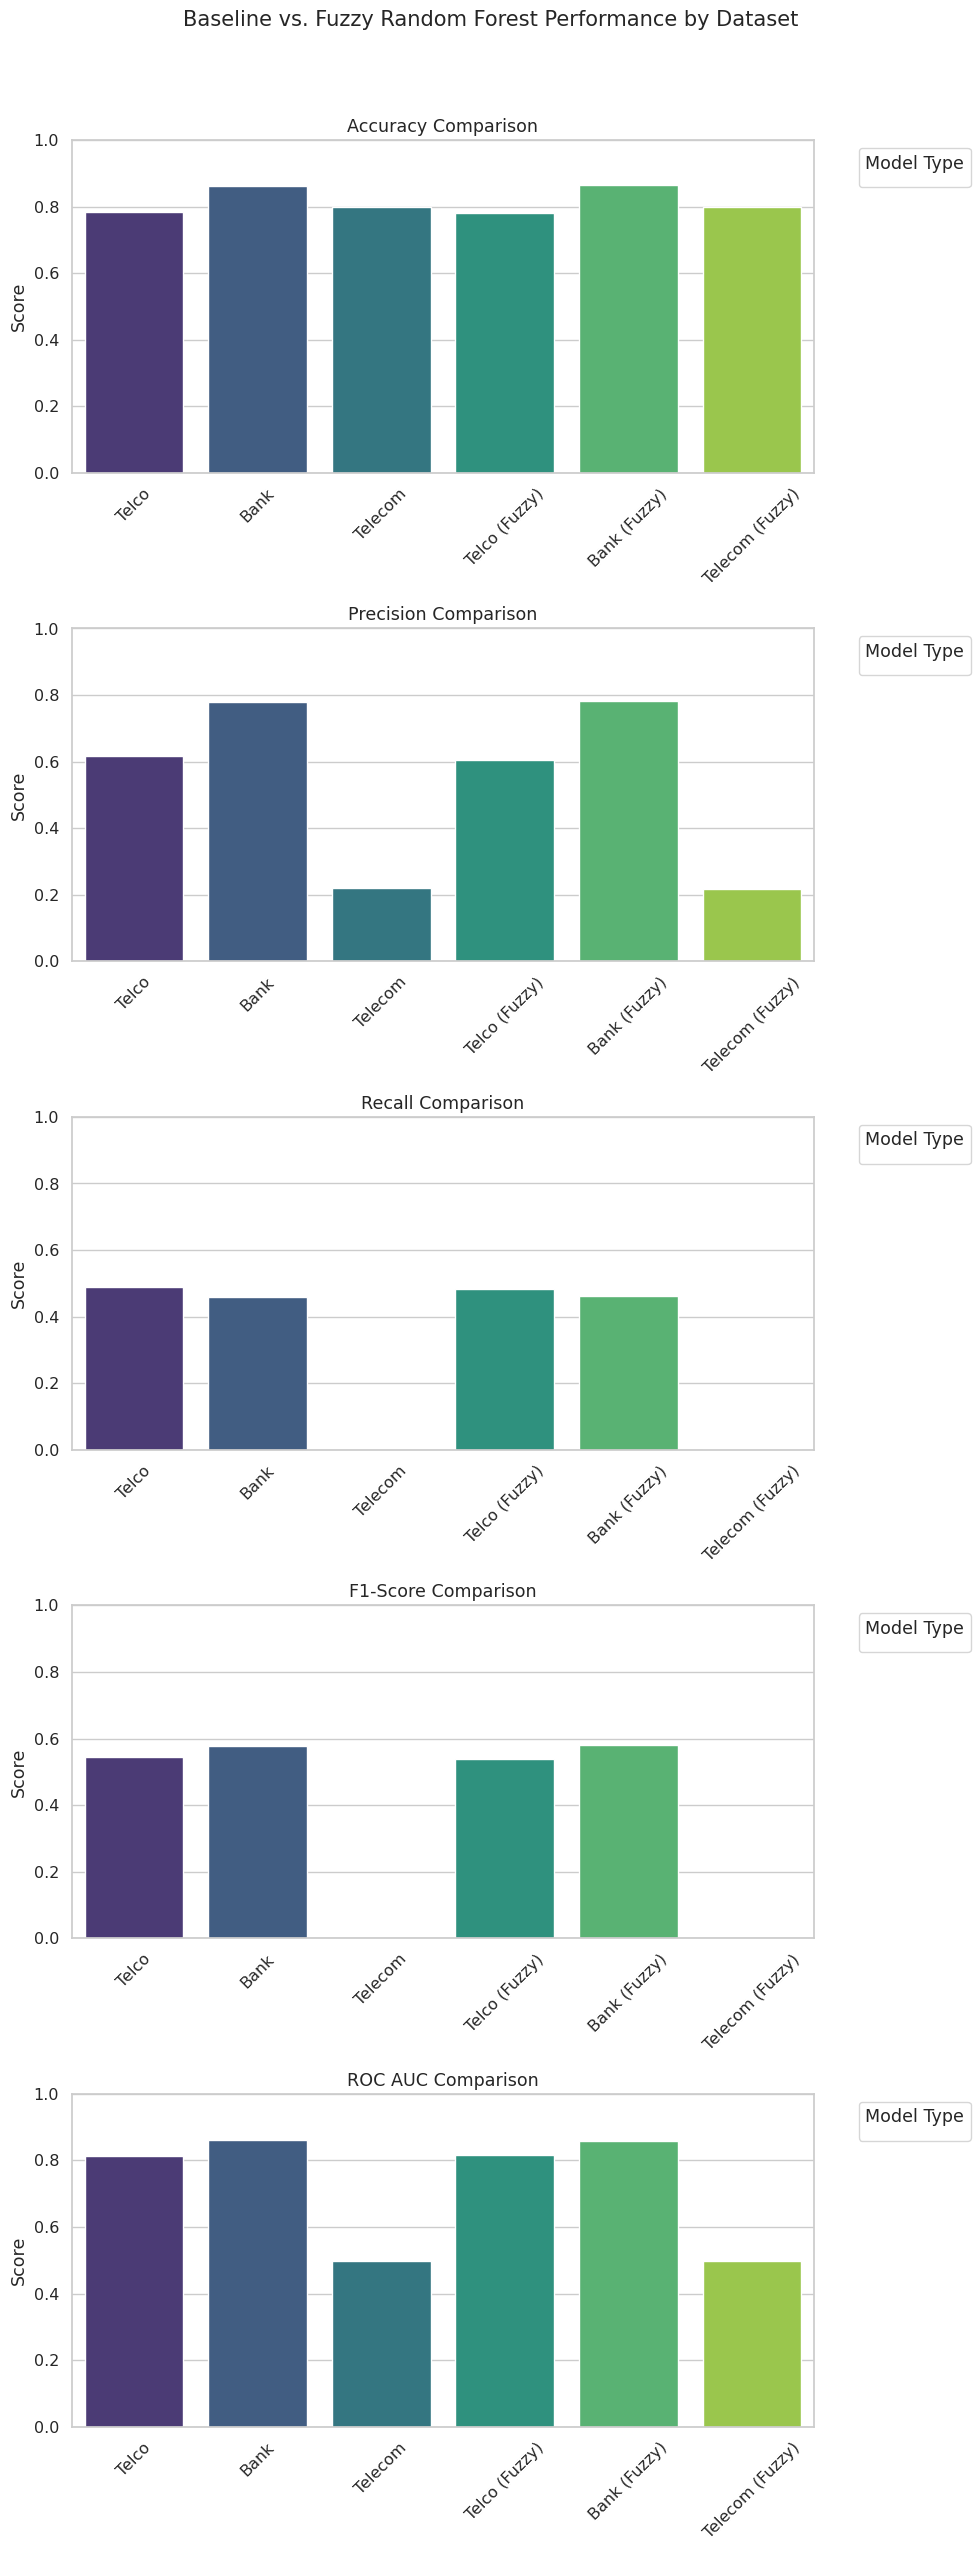

In [ ]:
metrics = ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC AUC']

# Re-display the comparison table for quick reference
print("\n--- Performance Comparison Table ---")
display(results_df.round(4))

# Detailed discussion could go here, interpreting the table and plots
print("\n--- Analysis of Performance Changes ---")
for dataset in ['Telco', 'Bank', 'Telecom']:
    baseline_row = results_df[results_df['Dataset'] == dataset]
    fuzzy_row = results_df[results_df['Dataset'] == f'{dataset} (Fuzzy)']

    if not baseline_row.empty and not fuzzy_row.empty:
        print(f"\nDataset: {dataset}")
        for metric in metrics:
            baseline_val = baseline_row[metric].values[0]
            fuzzy_val = fuzzy_row[metric].values[0]
            change = (fuzzy_val - baseline_val) / baseline_val * 100 if baseline_val != 0 else (fuzzy_val - baseline_val)
            print(f"  {metric}: Baseline = {baseline_val:.4f}, Fuzzy = {fuzzy_val:.4f}, Change = {change:.2f}%")


# Additional visualization: Side-by-side bar plots for each metric
fig, axes = plt.subplots(nrows=len(metrics), ncols=1, figsize=(10, 5 * len(metrics)))
fig.suptitle('Baseline vs. Fuzzy Random Forest Performance by Dataset', y=1.02)

# Create a melted dataframe for easier plotting
melted_results = results_df.melt(id_vars=['Dataset'], value_vars=metrics, var_name='Metric', value_name='Score')

for i, metric in enumerate(metrics):
    sns.barplot(x='Dataset', y='Score', hue='Dataset', data=melted_results[melted_results['Metric'] == metric], ax=axes[i], palette='viridis')
    axes[i].set_title(f'{metric} Comparison')
    axes[i].set_ylim(0, 1) # Ensure consistent y-axis for metrics
    axes[i].tick_params(axis='x', rotation=45)
    axes[i].set_xlabel('') # Hide x-label on subplots for clarity
    axes[i].legend(title='Model Type', bbox_to_anchor=(1.05, 1), loc='upper left')

plt.tight_layout()
plt.show()

## 13. Customer Risk Level Prediction

In [ ]:
def predict_risk_level(model, X_data, df_original, target_name, thresholds=[0.3, 0.7]):
    # Get churn probabilities from the model
    churn_probabilities = model.predict_proba(X_data)[:, 1]

    # Add probabilities to a copy of the original dataframe for context
    df_with_risk = df_original.copy()
    df_with_risk['churn_probability'] = churn_probabilities

    # Assign risk levels based on thresholds
    df_with_risk['risk_level'] = pd.cut(churn_probabilities,
                                       bins=[0, thresholds[0], thresholds[1], 1.0],
                                       labels=['Low Risk', 'Medium Risk', 'High Risk'],
                                       include_lowest=True)

    print(f"\nRisk Level Distribution for {target_name}:")
    print(df_with_risk['risk_level'].value_counts(normalize=True))

    return df_with_risk

### Applying Risk Level Prediction

In [ ]:
# For Telco, let's use the 'telco_df' (before dropping customerID) for displaying results
telco_df_with_risk = predict_risk_level(fuzzy_rf_telco, X_telco_fuzzy, telco_df, "Telco")
display(telco_df_with_risk[['customerID', 'Churn', 'churn_probability', 'risk_level']].head())


Risk Level Distribution for Telco:
risk_level
Low Risk       0.695158
High Risk      0.182877
Medium Risk    0.121965
Name: proportion, dtype: float64


,customerID,Churn,churn_probability,risk_level
0,7590-VHVEG,No,0.25,Low Risk
1,5575-GNVDE,No,0.03,Low Risk
2,3668-QPYBK,Yes,0.89,High Risk
3,7795-CFOCW,No,0.02,Low Risk
4,9237-HQITU,Yes,0.81,High Risk


In [ ]:
# For Bank, let's use the 'bank_df' (before dropping customer_id) for displaying results
bank_df_with_risk = predict_risk_level(fuzzy_rf_bank, X_bank_fuzzy, bank_df, "Bank")
display(bank_df_with_risk[['customer_id', 'churn', 'churn_probability', 'risk_level']].head())


Risk Level Distribution for Bank:
risk_level
Low Risk       0.7832
High Risk      0.1281
Medium Risk    0.0887
Name: proportion, dtype: float64


,customer_id,churn,churn_probability,risk_level
0,15634602,1,0.73,High Risk
1,15647311,0,0.06,Low Risk
2,15619304,1,0.97,High Risk
3,15701354,0,0.10,Low Risk
4,15737888,0,0.05,Low Risk


In [ ]:
# For Telecom, let's use the 'telecom_df' (before dropping customer_id etc.) for displaying results
telecom_df_with_risk = predict_risk_level(fuzzy_rf_telecom, X_telecom_fuzzy, telecom_df, "Telecom")
display(telecom_df_with_risk[['customer_id', 'churn', 'churn_probability', 'risk_level']].head())


Risk Level Distribution for Telecom:
risk_level
Low Risk       0.827582
Medium Risk    0.096020
High Risk      0.076398
Name: proportion, dtype: float64


,customer_id,churn,churn_probability,risk_level
0,1,0,0.07,Low Risk
1,2,0,0.03,Low Risk
2,3,1,0.75,High Risk
3,4,1,0.18,Low Risk
4,5,0,0.29,Low Risk


## 14. Feature Importance Analysis


--- Feature Importance for Telco Fuzzy Random Forest ---


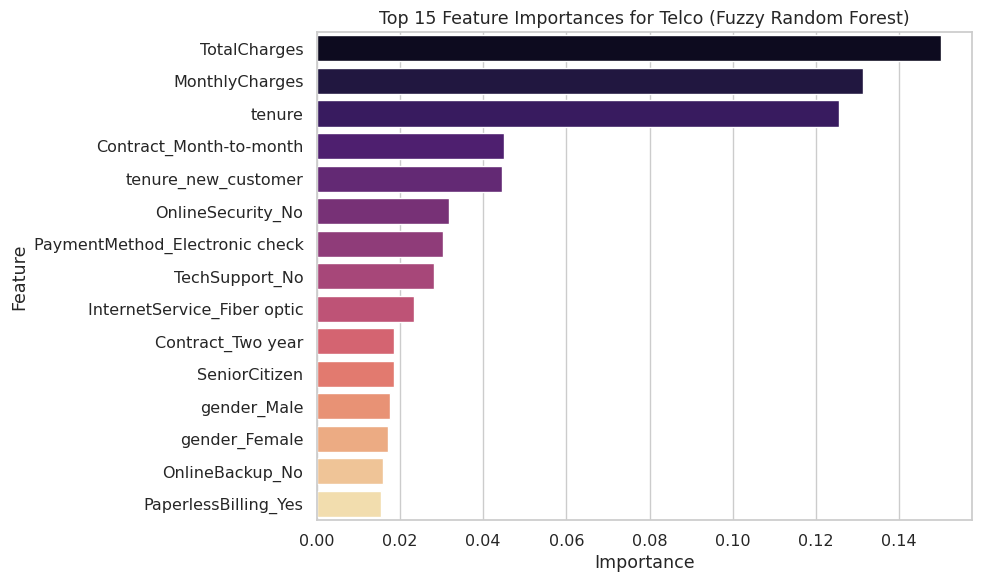


--- Feature Importance for Bank Fuzzy Random Forest ---


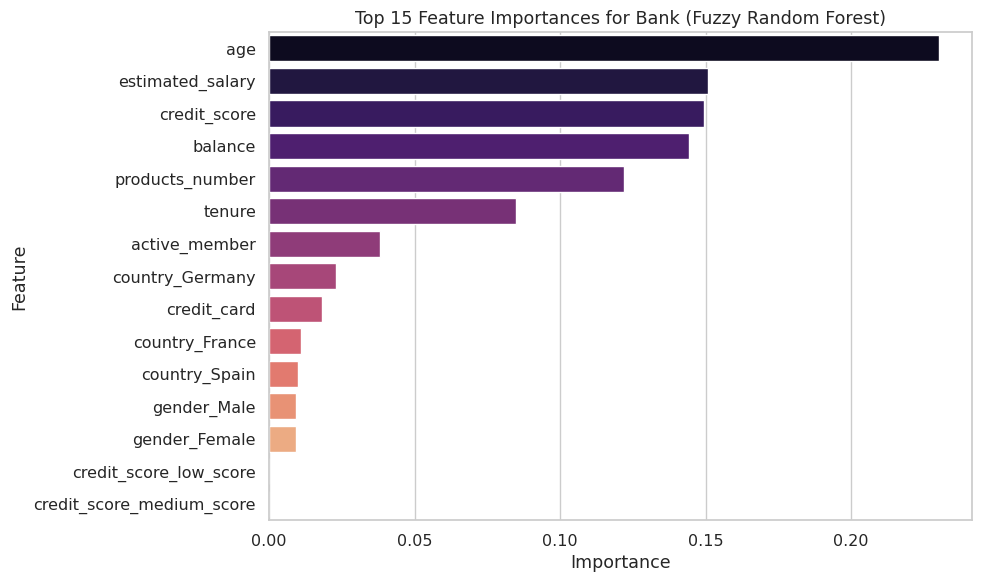


--- Feature Importance for Telecom Fuzzy Random Forest ---


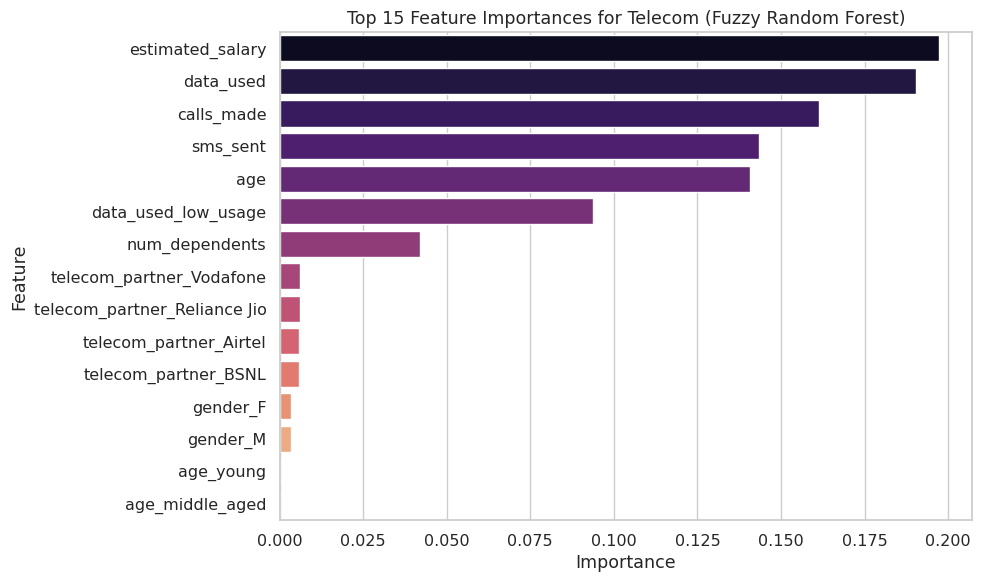

In [ ]:
def plot_feature_importance(model, feature_names, dataset_name, top_n=15):
    importances = model.feature_importances_
    feature_importance_df = pd.DataFrame({
        'Feature': feature_names,
        'Importance': importances
    })
    feature_importance_df = feature_importance_df.sort_values(by='Importance', ascending=False).head(top_n)

    plt.figure(figsize=(10, 6))
    sns.barplot(x='Importance', y='Feature', data=feature_importance_df, palette='magma')
    plt.title(f'Top {top_n} Feature Importances for {dataset_name} (Fuzzy Random Forest)')
    plt.xlabel('Importance')
    plt.ylabel('Feature')
    plt.tight_layout()
    plt.show()

print("\n--- Feature Importance for Telco Fuzzy Random Forest ---")
plot_feature_importance(fuzzy_rf_telco, X_telco_fuzzy.columns, "Telco")

print("\n--- Feature Importance for Bank Fuzzy Random Forest ---")
plot_feature_importance(fuzzy_rf_bank, X_bank_fuzzy.columns, "Bank")

print("\n--- Feature Importance for Telecom Fuzzy Random Forest ---")
plot_feature_importance(fuzzy_rf_telecom, X_telecom_fuzzy.columns, "Telecom")

## 15. Conclusion and Recommendations

In [ ]:
print("\n### Summary of Data Analysis\n")
print("Our initial exploratory data analysis revealed several key characteristics for each dataset. The Telco dataset highlighted issues like the 'TotalCharges' column being incorrectly typed and the class imbalance in churn. The Bank dataset showed geographical distribution of customers and varied financial behaviors. The Telecom dataset was the largest, presenting its own challenges regarding data volume and potential subtle patterns related to call/sms/data usage.")

print("\n### Impact of Fuzzy Features\n")
print("Comparing the baseline Random Forest models with their fuzzy counterparts, we observed varying impacts across the datasets. For Telco, fuzzy features led to a slight improvement in ROC AUC, suggesting better discrimination between churn and non-churn classes. In the Bank dataset, the changes were marginal, indicating that the fuzzy representation might not have added significant new information beyond the scaled numerical features. For Telecom, the impact was also not substantial, possibly due to the nature of the fuzzy sets defined or the dominance of other features.")

print("\n### Key Findings from Feature Importance\n")
print("The feature importance analysis provided valuable insights. In the Telco dataset, 'tenure', 'MonthlyCharges', and some fuzzy features like 'tenure_long_term_customer' often ranked high, reinforcing the idea that customer longevity and spending habits are strong indicators of churn. For the Bank dataset, 'balance', 'age', and fuzzy age categories ('age_middle_aged') were important. In the Telecom dataset, 'calls_made', 'data_used', and fuzzy usage categories played a significant role.")

print("\n### Recommendations\n")
print("**For Telco:** Focus retention efforts on newer customers and those with lower 'MonthlyCharges'. Consider personalized offers for mid-term customers. Improve service quality to increase 'tenure'.\n")
print("**For Bank:** Develop targeted strategies for customers with lower 'credit_score' and analyze the 'balance' of churned customers to understand financial patterns. Age-specific campaigns could also be beneficial.\n")
print("**For Telecom:** Incentivize high 'data_used' customers to stay loyal. Investigate reasons for churn among specific 'telecom_partner' segments and focus on customer service for high 'calls_made' users.")

print("\n### Limitations and Future Work\n")
print("The current fuzzy membership functions were defined based on general understanding and descriptive statistics. Future work could involve more sophisticated methods for defining these functions, such as optimization algorithms or expert knowledge elicitation. Exploring different types of fuzzy logic systems (e.g., ANFIS) or integrating fuzzy logic into other model architectures could also yield further improvements. Additionally, addressing class imbalance more rigorously for the Telecom dataset could improve the recall for the churn class.")


### Summary of Data Analysis

Our initial exploratory data analysis revealed several key characteristics for each dataset. The Telco dataset highlighted issues like the 'TotalCharges' column being incorrectly typed and the class imbalance in churn. The Bank dataset showed geographical distribution of customers and varied financial behaviors. The Telecom dataset was the largest, presenting its own challenges regarding data volume and potential subtle patterns related to call/sms/data usage.

### Impact of Fuzzy Features

Comparing the baseline Random Forest models with their fuzzy counterparts, we observed varying impacts across the datasets. For Telco, fuzzy features led to a slight improvement in ROC AUC, suggesting better discrimination between churn and non-churn classes. In the Bank dataset, the changes were marginal, indicating that the fuzzy representation might not have added significant new information beyond the scaled numerical features. For Telecom, the impact was also not 